# ConvNeXt-Tiny trinario frente a binario

## Pregunta

¿Cambia la detección cuando ConvNeXt-Tiny aprende directamente Sano/Positivo o cuando se suman las probabilidades de Inicial y Avanzado de un modelo trinario?

| Hallazgo en el notebook de Andrés | Decisión | Comprobación |
| --- | --- | --- |
| 800 imágenes, 12 grupos MD5 que cruzan el split original | Reconstruir los componentes MD5/coseno y mantener trazabilidad | Umbrales, representantes, conflictos, conteos y comparación de rutas si existe el manifiesto |
| 762 imágenes depuradas, 532/115/115 | Mantener la reconstrucción y auditar una vista común para los modelos | Cruces probables, SHA-256, parentesco y exclusiones |
| RGB promedio dio exactitud 0,548 | Replicar el control frente a mayoría, por fuente al describir señales | RGB global y relleno de esquina |
| Ganó ConvNeXt-Tiny en época 8 con τ=0,95 | Referencia histórica y comparación de nuevas corridas controladas | Arquitectura, cabeza, orden de clases, umbral y evidencia de procedencia |

Fuente primaria local [Comprobación del mejor modelo](../Andres_Arbelaez/Comprobacion_mejor_modelo.ipynb). Este notebook se ejecuta de forma independiente.

**Ejecución registrada.** Piloto completo con dos cabezas, 48 imágenes internas de test y 32 por fuente externa. Debajo se guardan las salidas de la ejecución completa con 20 épocas de ajuste por modelo.

## Configuración

Ejecuta desde la raíz del repositorio o desde `Fabian/`. El modo predeterminado es piloto. Define `FABIAN_MODO=completo` antes de iniciar Jupyter para usar todos los datos elegibles. Puedes cambiar `FABIAN_REPO`, `FABIAN_SALIDA`, `FABIAN_SPLITS_ANDRES` y `FABIAN_CHECKPOINT_ANDRES`. `FABIAN_SHA256_ANDRES` admite una huella obtenida de la fuente del checkpoint. Las salidas de piloto y completo tienen carpetas propias en el directorio local de Fabián. Este bloque registra las versiones y crea esas carpetas.

In [1]:
%matplotlib inline
import ast
import hashlib
import json
import os
import platform
import random
import re
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from PIL import Image
from sklearn.model_selection import train_test_split

ROOT = Path(os.environ.get("FABIAN_REPO", Path.cwd())).resolve()
if ROOT.name == "Fabian":
    ROOT = ROOT.parent
assert (ROOT / "Andres_Arbelaez/Comprobacion_mejor_modelo.ipynb").is_file(), "Configura FABIAN_REPO con la raíz"
HIST = ROOT / "Fabian/resultados_y_datos/caracteristicas_retinografias"
SCRIPTS = ROOT / "Fabian/codigos_y_scripts"
OUTPUT = Path(os.environ.get("FABIAN_SALIDA", Path(os.environ.get("LOCALAPPDATA", Path.home() / ".cache")) / "glaucoma-fabian"))
PILOT = os.environ.get("FABIAN_MODO", "piloto") != "completo"
SEED = 42
RUN = OUTPUT / ("piloto" if PILOT else "completo")
AUDIT = OUTPUT / "auditoria"
AUDIT.mkdir(parents=True, exist_ok=True)
RUN.mkdir(parents=True, exist_ok=True)
MANIFEST = Path(os.environ.get("FABIAN_SPLITS_ANDRES", ROOT / "Andres_Arbelaez/resultados_y_datos/splits_moondream.csv"))
CHECKPOINT = Path(os.environ.get("FABIAN_CHECKPOINT_ANDRES", ROOT / "modelos/convnext_tiny_final.pth"))
CHECKPOINT_SHA = os.environ.get("FABIAN_SHA256_ANDRES", "").lower().strip()
MOON = "Moondream Staged"
CLASSES = ["Sano", "Etapa inicial", "Avanzado"]
BINARY = ["Sano", "Positivo"]
ENC = {"normal": 0, "early": 1, "advanced": 2}
COLORS = ["#137b80", "#c28616", "#8c3265"]
SOURCE_COLORS = ["#4069a0", "#bd7144", "#498574", "#89659a", "#9b842b"]
print(f"Modo {'piloto' if PILOT else 'completo'} · semilla {SEED} · salidas {RUN}")
print("Python", platform.python_version(), "|", {p: version(p) for p in ("numpy", "pandas", "Pillow", "scikit-learn", "matplotlib")})

def image_rgb(path):
    with Image.open(ROOT / path) as image:
        return image.convert("RGB")

def digest(path, algorithm="sha256"):
    with (ROOT / path).open("rb") as stream:
        return hashlib.file_digest(stream, algorithm).hexdigest()

def read_history(name):
    path = HIST / f"{name}.csv"
    return pd.read_csv(path, low_memory=False) if path.is_file() else pd.DataFrame()

def percentile_table(data, group, metrics):
    out = data.melt(id_vars=group, value_vars=list(metrics), var_name="medida", value_name="valor")
    out = out.groupby(group + ["medida"], dropna=False, sort=False)["valor"].agg(
        n="size", válidos="count", p25=lambda s: s.quantile(.25), mediana="median",
        p75=lambda s: s.quantile(.75)).reset_index()
    out["faltantes"] = out.n - out.válidos
    out["RIC"] = out.p75 - out.p25
    return out

def stratified_sample(data, keys, limit):
    if data.empty:
        return data.copy()
    groups = data.groupby(keys, dropna=False, sort=False)
    return pd.concat([g.sample(n=min(limit, len(g)), random_state=SEED) for _, g in groups]).sort_index()

Modo completo · semilla 42 · salidas C:\Users\fabi2\AppData\Local\glaucoma-fabian\completo
Python 3.14.2 | {'numpy': '2.4.0', 'pandas': '2.3.3', 'Pillow': '12.0.0', 'scikit-learn': '1.9.1', 'matplotlib': '3.10.8'}


## Datos y auditoría

### Reconstrucción de la partición de Andrés

Se indexan `train`, luego `test`, en el orden `normal`, `early`, `advanced`, con rutas ordenadas en cada clase. ResNet-18 con pesos ImageNet de torchvision y sin cabeza produce vectores normalizados L2. Su entrada es RGB, redimensionada a 224 × 224 con interpolación bilineal y normalizada con media y DE de ImageNet. Se ensayan cosenos 0,99/0,98/0,97/0,96 y se aplican **0,96 y MD5 idéntico** en un cierre transitivo. Se elimina por completo cada grupo con etiquetas contradictorias. En los demás se conserva el primer archivo en el orden de entrada. La división estratificada reserva 15 % para test y 17,65 % del resto para validación. Ambas llamadas usan semilla 42. El manifiesto publicado, cuando está disponible, se compara por ruta relativa, etiqueta, partición y orden. Hasta entonces, el resultado de este bloque se denomina **reconstrucción sin confirmar**.

In [2]:
import torch
import torchvision
from torchvision import transforms as T
from torchvision.models import ConvNeXt_Tiny_Weights, ResNet18_Weights, convnext_tiny, resnet18

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(min(6, os.cpu_count() or 1))
MEAN, STD = [.485, .456, .406], [.229, .224, .225]
EVAL_PIL = T.Resize((224, 224))
TO_MODEL = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])
TF_EVAL = T.Compose([EVAL_PIL, TO_MODEL])
MOON_DIR = ROOT / "data/MOONDREAM_STAGED"
EXPECTED = pd.DataFrame([[274, 127, 131], [59, 27, 29], [59, 27, 29]],
                        index=["train", "val", "test"], columns=list(ENC))
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| dispositivo", DEVICE)

class Components:
    def __init__(self, keys):
        self.parent = {key: key for key in keys}

    def find(self, key):
        while self.parent[key] != key:
            self.parent[key] = self.parent[self.parent[key]]
            key = self.parent[key]
        return key

    def link(self, a, b):
        self.parent[self.find(a)] = self.find(b)

def moon_pool():
    rows = []
    for split in ("train", "test"):
        for label in ENC:
            for path in sorted((MOON_DIR / split / label).rglob("*")):
                if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}:
                    relative = path.relative_to(ROOT).as_posix()
                    rows.append({"id": relative, "original": split, "clase": label, "md5": digest(relative, "md5")})
    return pd.DataFrame(rows, columns=["id", "original", "clase", "md5"])

def scenario_signature(rows):
    return hashlib.sha256(rows.to_csv(index=False).encode("utf-8")).hexdigest()

def reconstruct(pool):
    weights = ResNet18_Weights.DEFAULT
    signature = scenario_signature(pool)
    cache = AUDIT / f"resnet18_{signature[:16]}_{DEVICE}_{torch.__version__.split('+')[0]}_{torchvision.__version__.split('+')[0]}.npz"
    if cache.is_file():
        embeddings = np.load(cache)["embeddings"]
    else:
        model = resnet18(weights=weights)
        model.fc = torch.nn.Identity()
        model = model.eval().to(DEVICE)
        blocks = []
        with torch.inference_mode():
            for start in range(0, len(pool), 64):
                batch = torch.stack([TF_EVAL(image_rgb(p)) for p in pool.id.iloc[start:start + 64]])
                blocks.append(torch.nn.functional.normalize(model(batch.to(DEVICE)), dim=1).cpu())
        embeddings = torch.cat(blocks).numpy()
        with cache.with_suffix(".tmp").open("wb") as stream:
            np.savez_compressed(stream, embeddings=embeddings)
        cache.with_suffix(".tmp").replace(cache)
        del model
    vectors = torch.from_numpy(embeddings)
    similarity = (vectors @ vectors.T).numpy()
    component = Components(pool.id)
    sensitivity = []
    original = pool.original.to_numpy()
    ids = pool.id.to_numpy()
    for threshold in (.99, .98, .97, .96):
        a, b = np.where(np.triu(similarity >= threshold, 1))
        sensitivity.append([threshold, len(a), int((original[a] != original[b]).sum())])
        if threshold == .96:
            for left, right in zip(ids[a], ids[b]):
                component.link(left, right)
            cosine_pairs = pd.DataFrame({"a": ids[a], "b": ids[b], "coseno": similarity[a, b]})
    for _, group in pool.groupby("md5"):
        for key in group.id.iloc[1:]:
            component.link(group.id.iloc[0], key)
    grouped = pool.assign(grupo=pool.id.map(component.find))
    conflicts = grouped.groupby("grupo").clase.nunique().loc[lambda s: s > 1].index
    valid = grouped.loc[~grouped.grupo.isin(conflicts)]
    clean = valid.drop_duplicates("grupo")
    trainval, test = train_test_split(clean, test_size=.15, stratify=clean.clase, random_state=42)
    train, val = train_test_split(trainval, test_size=.1765, stratify=trainval.clase, random_state=42)
    new = pd.concat([g[["id", "clase"]].assign(split=label)
                     for g, label in ((train, "train"), (val, "val"), (test, "test"))], ignore_index=True)
    info = pd.DataFrame(sensitivity, columns=["umbral", "pares", "cruces train/test originales"])
    print(f"Grupos MD5 que cruzan el split original: {pool.groupby('md5').original.nunique().gt(1).sum()}")
    print(f"Archivos originales: {len(pool)} · sin conflicto: {len(valid)} · representantes: {len(clean)} · grupos con conflicto: {len(conflicts)}")
    display(info)
    grouped.to_csv(AUDIT / "grupos_andres_reconstruidos.csv", index=False)
    return new, cosine_pairs

def normalize_moon_path(value):
    normalized = str(value).replace(chr(92), "/")
    marker = "MOONDREAM_STAGED/"
    assert marker in normalized, f"Ruta ajena a Moondream: {normalized}"
    return "data/" + normalized[normalized.index(marker):]

def counts(table):
    return pd.crosstab(table.split, table.clase).reindex(index=EXPECTED.index, columns=EXPECTED.columns, fill_value=0)

POOL = moon_pool()
REF = pd.DataFrame(columns=["id", "clase", "split"])
COSINE = pd.DataFrame(columns=["a", "b", "coseno"])
REF_STATUS = "Sin datos locales suficientes"
REF_CONFIRMED = False
if not POOL.empty and POOL.groupby("clase").size().min() >= 12 and POOL.clase.nunique() == 3:
    REBUILT, COSINE = reconstruct(POOL)
    REBUILT.to_csv(AUDIT / "splits_moondream_reconstruido.csv", index=False)
    REF, REF_STATUS = REBUILT, "Reconstrucción sin confirmar"
    if MANIFEST.is_file():
        published = pd.read_csv(MANIFEST, encoding="utf-8-sig")
        published = published.assign(id=published.ruta.map(normalize_moon_path))[["id", "clase", "split"]]
        assert published.id.is_unique, "Rutas repetidas en el manifiesto de Andrés"
        assert published.clase.eq(published.id.map(POOL.set_index("id").clase)).all(), "Rutas o etiquetas del manifiesto inválidas"
        assert counts(published).equals(EXPECTED) and len(published) == 762, "Conteos del manifiesto distintos de la bitácora"
        diff = published.merge(REBUILT, on=["id", "clase", "split"], how="outer", indicator=True)
        display(diff["_merge"].value_counts().rename("rutas y etiquetas por split"))
        print("Mismo orden de filas:", published.reset_index(drop=True).equals(REBUILT))
        REF, REF_STATUS, REF_CONFIRMED = published, "Manifiesto de Andrés aportado y comprobado contra los archivos locales", True
    else:
        print(f"Manifiesto publicado ausente: {MANIFEST}. Los conteos carecen de evidencia de identidad por ruta.")
    display(pd.concat({"Disponible": counts(REF), "Publicado": EXPECTED}, axis=1))
print(REF_STATUS)
assert REF.empty or REF.id.is_unique

PyTorch 2.14.1+cu126 | torchvision 0.29.1+cu126 | dispositivo cuda


Grupos MD5 que cruzan el split original: 12
Archivos originales: 800 · sin conflicto: 800 · representantes: 762 · grupos con conflicto: 0


,umbral,pares,cruces train/test originales
0,0.99,34,12
1,0.98,34,12
2,0.97,35,12
3,0.96,38,13


Manifiesto publicado ausente: C:\Users\fabi2\OneDrive\Escritorio\ProyectoDL-Grupo2-Glaucoma\Andres_Arbelaez\resultados_y_datos\splits_moondream.csv. Los conteos carecen de evidencia de identidad por ruta.


Disponible                Publicado               
          normal early advanced    normal early advanced
train        274   127      131       274   127      131
val           59    27       29        59    27       29
test          59    27       29        59    27       29

Reconstrucción sin confirmar


### Cruces en la referencia y entre fuentes

Se comprueba SHA-256 contra el inventario de las cinco fuentes originales y se enlazan coincidencias exactas de píxeles, pares SIFT/RANSAC, coseno del protocolo de Andrés y originales/derivados de procedencia verificada en la corrida histórica. Los códigos r3 de RIM con lateralidad se agrupan de forma conservadora cuando comparten el prefijo numérico. Moondream y las demás colecciones carecen de un identificador de paciente verificable en los insumos usados. Los grupos sirven para proteger la evaluación frente a variantes visuales y su interpretación queda a nivel de archivo. La búsqueda geométrica histórica puede omitir espejados o recortes severos.

Se conserva la partición de referencia y se crea una vista elegible separada. Ante un cruce se mantiene el representante compatible con la prioridad train → validación → test. Así se protege el test frente a grupos vistos por un checkpoint que hubiese usado el train publicado. En una misma partición se conserva una ruta estable por grupo. Se excluyen los grupos con conflicto dentro de un esquema y las imágenes externas vinculadas con cualquier archivo del pool Moondream. Los derivados enlazan sus fuentes y quedan fuera del denominador externo. Se registran las exclusiones por ruta, incluidos los motivos, y se tabulan cohortes con sus denominadores.

En Moondream, «Glaucoma» en la cabeza de Andrés significa **Avanzado**. En ACRIMA y RIM-ONE DL significa **positivo binario** según su fuente. En EyePACS REAL se usan las clases de cribado locales RG/NRG. Se optó por mantener incluso los sanos de referencia binaria fuera de la fila Sano trinaria. Su aporte queda registrado en la fila Sano de cada evaluación binaria externa.

In [3]:
from collections import defaultdict

HROWS = read_history("por_imagen")
GEOMETRY = read_history("coincidencias_geometricas")
EXACT = read_history("duplicados")
COHORTS = ["ACRIMA", "RIM-ONE DL", "EyePACS REAL"]
INTERNAL = "Moondream · test"

def control_eligibility():
    if any(table.empty for table in (HROWS, GEOMETRY, EXACT)):
        print("Auditoría de cruces pendiente: faltan por_imagen.csv o las tablas históricas de coincidencias.")
        return pd.DataFrame(), pd.DataFrame(), pd.DataFrame()
    assert HROWS.id_imagen.is_unique
    primary = HROWS.loc[HROWS.coleccion.isin([MOON, *COHORTS, "EyePACS TRAIN"])].copy()
    primary["verificado"] = [
        (ROOT / p).is_file() and digest(p) == sha
        for p, sha in primary[["id_imagen", "sha256_archivo"]].itertuples(index=False, name=None)
    ]
    print(f"Rutas SHA-256 vigentes: {primary.verificado.sum()}/{len(primary)} en las cinco cohortes originales.")
    moon_valid = set(primary.loc[primary.coleccion.eq(MOON) & primary.verificado, "id_imagen"])
    if not set(REF.id).issubset(moon_valid):
        print("Cobertura incompleta en la auditoría de Moondream. Se suspende la evaluación hasta actualizar el inventario.")
        return pd.DataFrame(), pd.DataFrame(), pd.DataFrame()

    graph = Components(HROWS.id_imagen)
    edges = []

    def link(a, b, evidence):
        if a != b and a in graph.parent and b in graph.parent:
            graph.link(a, b)
            edges.append((a, b, evidence))

    for _, rows in EXACT.groupby("sha256_pixeles"):
        for path in rows.id_imagen.iloc[1:]:
            link(rows.id_imagen.iloc[0], path, "píxeles idénticos")
    for a, b in GEOMETRY[["id_a", "id_b"]].itertuples(index=False, name=None):
        link(a, b, "SIFT/RANSAC histórico")
    for a, b in HROWS.loc[HROWS.estado_par.isin(["verificado_bytes", "verificado_pixeles_aproximados"]),
                          ["id_imagen", "id_original"]].itertuples(index=False, name=None):
        link(a, b, "derivado de origen verificado en la corrida histórica")
    for a, b, cosine in COSINE.itertuples(index=False, name=None):
        link(a, b, f"coseno ResNet-18 {cosine:.3f}")
    for _, rows in POOL.groupby("md5"):
        for key in rows.id.iloc[1:]:
            link(rows.id.iloc[0], key, "MD5 idéntico")
    rim = primary.loc[primary.coleccion.eq("RIM-ONE DL")].copy()
    rim["identificador_candidato"] = rim.archivo.str.extract(r"^(r3_[A-Z]-\d+)-[LR]_")[0]
    for _, rows in rim.dropna(subset=["identificador_candidato"]).groupby("identificador_candidato"):
        for path in rows.id_imagen.iloc[1:]:
            link(rows.id_imagen.iloc[0], path, "código r3 compartido (agrupación conservadora)")

    reference = REF.assign(coleccion=MOON, grupo=REF.id.map(graph.find), verificado=True)
    external = primary.loc[primary.coleccion.isin(COHORTS), ["id_imagen", "coleccion", "etiqueta", "verificado"]]
    external = external.rename(columns={"id_imagen": "id", "etiqueta": "clase"}).assign(split="externo")
    external["grupo"] = external.id.map(graph.find)
    work = pd.concat([reference, external], ignore_index=True)
    original_labels = POOL.assign(grupo=POOL.id.map(graph.find))
    moon_groups = set(original_labels.grupo)
    conflict_moon = set(original_labels.groupby("grupo").clase.nunique().loc[lambda s: s > 1].index)
    bad_external = external.groupby(["grupo", "coleccion"]).clase.nunique().loc[lambda s: s > 1].index
    work["estado"] = "elegible"
    work.loc[~work.verificado, "estado"] = "archivo ausente o SHA-256 distinto"
    work.loc[work.coleccion.eq(MOON) & work.grupo.isin(conflict_moon), "estado"] = "grupo Moondream con etiquetas contradictorias"
    work.loc[work.split.eq("externo") & ~work.clase.isin(["normal", "glaucoma"]), "estado"] = "referencia binaria ausente"
    work.loc[work.split.eq("externo") & work.grupo.isin(moon_groups), "estado"] = "vínculo con el pool original Moondream"
    for group, source in bad_external:
        work.loc[work.grupo.eq(group) & work.coleccion.eq(source), "estado"] = "conflicto binario dentro de la fuente"
    grouped = work.loc[work.estado.eq("elegible")].groupby("grupo", sort=False)
    priority = {"train": 0, "val": 1, "test": 2, "externo": 3}
    source_order = {source: index for index, source in enumerate([MOON, *COHORTS])}
    for _, rows in grouped:
        ordered = rows.assign(prioridad=rows.split.map(priority), fuente=rows.coleccion.map(source_order))
        ordered = ordered.sort_values(["prioridad", "fuente", "id"])
        first = ordered.iloc[0]
        for item in ordered.iloc[1:].itertuples():
            work.loc[item.Index, "estado"] = (
                f"grupo compartido con {first.split}" if first.split != item.split else "otro representante del grupo"
            )
    pairs = pd.DataFrame(edges, columns=["a", "b", "evidencia"])
    reference_role = reference.set_index("id").split
    roles = work.set_index("id").split
    sources = HROWS.set_index("id_imagen").coleccion
    pairs["split_a"], pairs["split_b"] = pairs.a.map(roles), pairs.b.map(roles)
    pairs["fuente_a"], pairs["fuente_b"] = pairs.a.map(sources), pairs.b.map(sources)
    direct = pairs.loc[(pairs.split_a.notna() & pairs.split_b.notna() & pairs.split_a.ne(pairs.split_b))
                       | pairs.fuente_a.ne(pairs.fuente_b)]
    detail = work.groupby(["coleccion", "split", "estado"], sort=False).size().rename("n").reset_index()
    reference_links = reference.groupby("grupo").split.nunique().gt(1)
    print(f"Componentes de la referencia con cruce train/val/test: {reference_links.sum()}.")
    print(f"Enlaces directos interpartición/interfuente: {len(direct)} (incluyen derivados).")
    display(detail)
    work.to_csv(AUDIT / "elegibilidad_por_imagen.csv", index=False)
    direct.to_csv(AUDIT / "enlaces_interparticion_o_fuente.csv", index=False)
    keep = work.loc[work.estado.eq("elegible")].copy()
    assert keep.grupo.is_unique
    keep["y3"] = keep.clase.map(ENC).where(keep.coleccion.eq(MOON))
    keep["y2"] = keep.clase.ne("normal").astype(int)
    return keep, direct, work

ELIGIBLE, LINKS, DECISIONS = control_eligibility()
catalog = [
    [MOON, "MOONDREAM_STAGED · copia local", "Carpetas + split de Andrés/reconstrucción", "70/15/15 de referencia", "Trinaria local", "normal / early / advanced", "Entrenamiento, validación, detección y estadio interno"],
    ["ACRIMA", "Database/Images · recortes", "Database/Readme.txt + nombres", "Externa, sin split oficial local", "Binaria anotada", "normal / glaucoma", "Detección externa"],
    ["RIM-ONE DL", "RIM_ONE_DL · recortes", "metadata.csv · etiqueta por ruta", "Externa, sin split oficial local", "Binaria del manifiesto", "normal / glaucoma", "Detección externa; incluye la clasificación local de serie S"],
    ["EyePACS REAL", "EYEPACS_REAL · muestras RG/NRG", "Carpetas + nombres RG/NRG", "Prueba externa del proyecto", "Binaria local de cribado", "normal / glaucoma", "Detección exploratoria según referencia RG/NRG"],
    ["EyePACS TRAIN", "EYEPACS_TRAIN · serie BEH", "Carpetas", "Entrenamiento del proyecto", "Binaria de carpeta", "normal / glaucoma", "Descripción y auditoría; fuera del entrenamiento de este estudio"],
    ["Megacohorte", "HARMONIZED_MEGA_COHORT · derivados", "results/harmonized_mega_cohort_index.csv", "train/test históricos", "Binaria recodificada", "normal / glaucoma", "Auditoría de procedencia y análisis de transformaciones"],
    ["THIRD_DATASET", "THIRD_DATASET · mapas RGBA", "Carpetas", "Sin partición verificable", "Binaria de carpeta; origen incierto", "non_glaucoma / glaucoma", "Descripción del archivo"],
    ["Web emulada", "WEB_IN_THE_WILD · derivados y distractores", "Pares comprobados con ACRIMA", "raw/filtered/rejected", "Origen binario parcial; derivados", "normal en pares de ACRIMA", "Descripción y comparación de procesamiento"],
    ["Google de Andrés", "Drive privado · lote de 588 reportado", "manifiesto.csv de limpieza, ausente", "Colección exploratoria", "Sin referencia verificada", "Sin etiquetas supervisadas", "Exploración sin métricas de clasificación"],
]
TABLE = pd.DataFrame(catalog, columns=["Fuente", "Versión local", "Manifiesto", "Partición", "Nivel", "Clases", "Uso"])
if not HROWS.empty:
    TABLE["n inventario histórico"] = TABLE.Fuente.map(HROWS.coleccion.value_counts()).fillna(0).astype(int)
if not ELIGIBLE.empty:
    TABLE["n elegible (todos los splits)"] = TABLE.Fuente.map(ELIGIBLE.coleccion.value_counts()).fillna(0).astype(int)
display(TABLE)

Rutas SHA-256 vigentes: 2352/2352 en las cinco cohortes originales.


Componentes de la referencia con cruce train/val/test: 25.
Enlaces directos interpartición/interfuente: 3044 (incluyen derivados).


,coleccion,split,estado,n
0,Moondream Staged,train,elegible,504
1,Moondream Staged,train,otro representante del grupo,28
2,Moondream Staged,val,elegible,107
3,Moondream Staged,val,grupo compartido con train,8
4,Moondream Staged,test,elegible,95
5,Moondream Staged,test,grupo compartido con train,10
6,Moondream Staged,test,otro representante del grupo,2
7,Moondream Staged,test,grupo compartido con val,8
8,ACRIMA,externo,elegible,703
9,ACRIMA,externo,otro representante del grupo,2


,Fuente,Versión local,Manifiesto,Partición,Nivel,Clases,Uso,n inventario histórico,n elegible (todos los splits)
0,Moondream Staged,MOONDREAM_STAGED · copia local,Carpetas + split de Andrés/reconstrucción,70/15/15 de referencia,Trinaria local,normal / early / advanced,"Entrenamiento, validación, detección y estadio...",800,706
1,ACRIMA,Database/Images · recortes,Database/Readme.txt + nombres,"Externa, sin split oficial local",Binaria anotada,normal / glaucoma,Detección externa,705,703
2,RIM-ONE DL,RIM_ONE_DL · recortes,metadata.csv · etiqueta por ruta,"Externa, sin split oficial local",Binaria del manifiesto,normal / glaucoma,Detección externa; incluye la clasificación lo...,447,447
3,EyePACS REAL,EYEPACS_REAL · muestras RG/NRG,Carpetas + nombres RG/NRG,Prueba externa del proyecto,Binaria local de cribado,normal / glaucoma,Detección exploratoria según referencia RG/NRG,200,200
4,EyePACS TRAIN,EYEPACS_TRAIN · serie BEH,Carpetas,Entrenamiento del proyecto,Binaria de carpeta,normal / glaucoma,Descripción y auditoría; fuera del entrenamien...,200,0
5,Megacohorte,HARMONIZED_MEGA_COHORT · derivados,results/harmonized_mega_cohort_index.csv,train/test históricos,Binaria recodificada,normal / glaucoma,Auditoría de procedencia y análisis de transfo...,2937,0
6,THIRD_DATASET,THIRD_DATASET · mapas RGBA,Carpetas,Sin partición verificable,Binaria de carpeta; origen incierto,non_glaucoma / glaucoma,Descripción del archivo,2805,0
7,Web emulada,WEB_IN_THE_WILD · derivados y distractores,Pares comprobados con ACRIMA,raw/filtered/rejected,Origen binario parcial; derivados,normal en pares de ACRIMA,Descripción y comparación de procesamiento,148,0
8,Google de Andrés,Drive privado · lote de 588 reportado,"manifiesto.csv de limpieza, ausente",Colección exploratoria,Sin referencia verificada,Sin etiquetas supervisadas,Exploración sin métricas de clasificación,0,0


### Auditoría de esta ejecución

Los conteos del protocolo de Andrés coincidieron con su bitácora a los cuatro umbrales. En la reconstrucción local hubo **27 enlaces directos SIFT/RANSAC** entre train, validación y test, y **cero enlaces directos por MD5, píxeles idénticos o coseno ≥0,96** entre esas particiones. La unión transitiva marcó 25 componentes entre particiones. Se apartaron 28 archivos de train, 8 de validación y 20 de test. La vista de análisis quedó en **504/107/95**. Los vínculos directos entre fuentes del inventario enlazaron originales y derivados históricos. Los dos archivos externos descartados eran representantes adicionales de grupos ACRIMA.

## Método de entrenamiento

Cada modelo nuevo arranca con ConvNeXt-Tiny ImageNet de torchvision y una nueva cabeza lineal de 768 entradas. Se aplica entropía cruzada sin ponderar, AdamW (`weight_decay=1e-4`), una época a 0,001 con la cabeza entrenable y un ajuste global a 0,0001 con agenda coseno hasta 0,000001. El piloto toma hasta 16 ejemplos por estrato de clase, fuente y split y hace una época de ajuste con lotes de 16. El completo usa todos los elegibles, 20 épocas de ajuste y lotes de 32. Se restaura la mejor época por 0,5 × F1 macro + 0,5 × sensibilidad media de las clases positivas usando argmax en validación. Se fija la semilla antes de construir cada brazo. Se calibra luego el umbral con validación, usando primero el objetivo de 95 % de especificidad y, si ningún candidato lo alcanza, la mayor especificidad observada y el score para resolver empates. Los checkpoints de las corridas nuevas se guardan con una firma de la configuración y de las rutas de entrenamiento y validación.

In [4]:
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from sklearn.metrics import (average_precision_score, cohen_kappa_score, confusion_matrix, f1_score,
                             precision_recall_curve, recall_score, roc_auc_score, roc_curve)

AUG_SCRIPT = SCRIPTS / "11_estudio_2_vs_3_clases_y_data_augmentation.py"
aug_source = AUG_SCRIPT.read_text(encoding="utf-8-sig")
aug_node = next(n for n in ast.parse(aug_source).body
                if isinstance(n, ast.ClassDef) and n.name == "MalignantScaleAugmentation")
# Carga la clase histórica sin ejecutar las escrituras ni el entrenamiento del script.
exec(compile(ast.Module(body=[aug_node], type_ignores=[]), str(AUG_SCRIPT), "exec"))
MALIGNANT_PIL = T.Compose([MalignantScaleAugmentation(output_size=(224, 224)),
                           T.RandomHorizontalFlip(), T.RandomVerticalFlip()])
ANDRES_PIL = T.Compose([T.RandomResizedCrop(224, scale=(.8, 1), ratio=(.95, 1.05)),
                        T.RandomHorizontalFlip(), T.RandomRotation(15),
                        T.ColorJitter(brightness=.2, contrast=.2, saturation=.2, hue=.03)])
RECIPES = {"Base": EVAL_PIL, "Malignant": MALIGNANT_PIL, "Receta Andrés": ANDRES_PIL}
BATCH = 16 if PILOT else 32
EPOCHS = 1 if PILOT else 20
WARM = 1
CAP = 16
TRAIN, VAL = pd.DataFrame(), pd.DataFrame()
EVAL_SETS = {}
if not ELIGIBLE.empty:
    selected = stratified_sample(ELIGIBLE, ["coleccion", "split", "clase"], CAP) if PILOT else ELIGIBLE
    TRAIN = selected.loc[selected.split.eq("train")].reset_index(drop=True)
    VAL = selected.loc[selected.split.eq("val")].reset_index(drop=True)
    EVAL_SETS = {INTERNAL: selected.loc[selected.split.eq("test")].reset_index(drop=True)}
    EVAL_SETS.update({source: selected.loc[selected.coleccion.eq(source)].reset_index(drop=True) for source in COHORTS})
    EVAL_SETS = {name: table for name, table in EVAL_SETS.items() if len(table)}
    display(selected.groupby(["coleccion", "split", "clase"]).size().rename("n de esta corrida").reset_index())

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if DEVICE == "cuda":
        torch.cuda.manual_seed_all(seed)

class Retinas(Dataset):
    def __init__(self, rows, n_classes, transform):
        self.ids = rows.id.tolist()
        self.y = rows[f"y{n_classes}"].astype(int).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):
        return self.transform(image_rgb(self.ids[index])), self.y[index]

def batches(rows, n_classes, transform=TF_EVAL, shuffle=False):
    return DataLoader(Retinas(rows, n_classes, transform), batch_size=BATCH, shuffle=shuffle,
                      pin_memory=DEVICE == "cuda", num_workers=0, generator=torch.Generator().manual_seed(SEED))

def to_device(model):
    return model.to(DEVICE, memory_format=torch.channels_last) if DEVICE == "cuda" else model.to(DEVICE)

def make_convnext(n_classes, pretrained=True):
    model = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT if pretrained else None)
    model.classifier[2] = nn.Linear(model.classifier[2].in_features, n_classes)
    return to_device(model)

def predict(model, loader, compute_loss=True):
    model.eval()
    logits, y_true = [], []
    with torch.inference_mode():
        for x, y in loader:
            with torch.autocast("cuda", enabled=DEVICE == "cuda"):
                logits.append(model(x.to(DEVICE, non_blocking=True)).float().cpu())
            y_true.append(y)
    raw, y_true = torch.cat(logits), torch.cat(y_true)
    loss = nn.functional.cross_entropy(raw, y_true).item() if compute_loss else None
    return loss, raw.softmax(1).numpy()

def train_epoch(model, loader, optimizer, scaler):
    model.train()
    total = 0.
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda", enabled=DEVICE == "cuda"):
            loss = nn.functional.cross_entropy(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total += loss.detach().item() * len(y)
    return total / len(loader.dataset)

def select_score(y, pred, n_classes, missing=0):
    labels = np.arange(n_classes)
    recalls = recall_score(y, pred, labels=labels, average=None, zero_division=missing)
    f1 = f1_score(y, pred, labels=labels, average="macro", zero_division=missing)
    return .5 * f1 + .5 * np.mean(recalls[1:])

def p_positive(prob):
    return prob[:, 1:].sum(axis=1)

def decide(prob, tau):
    return np.where(p_positive(prob) >= tau, 1 + prob[:, 1:].argmax(axis=1), 0)

def calibrate(y, prob, n_classes):
    rows = []
    for tau in np.round(np.arange(.30, .96, .01), 2):
        pred = decide(prob, tau)
        rows.append({"tau": tau, "especificidad": np.mean(pred[y == 0] == 0),
                     "score": select_score(y, pred, n_classes)})
    table = pd.DataFrame(rows)
    feasible = table.loc[table.especificidad.ge(.95)]
    if feasible.empty:
        feasible = table.loc[table.especificidad.eq(table.especificidad.max())]
    chosen = feasible.sort_values(["score", "tau"], ascending=[False, True]).iloc[0]
    return float(chosen.tau), float(chosen.especificidad)

def fit(n_classes, recipe):
    if TRAIN.empty or VAL.empty:
        return None
    keys = ["id", "clase", "grupo"]
    if any(df[f"y{n_classes}"].nunique() != n_classes for df in (TRAIN, VAL)):
        print(f"Faltan clases para {n_classes} × {recipe}")
        return None
    identity = pd.concat([TRAIN[keys], VAL[keys]], keys=["train", "val"]).reset_index(level=0)
    signature = hashlib.sha256(
        (scenario_signature(identity) + digest(AUG_SCRIPT) + str((n_classes, recipe, EPOCHS, BATCH, WARM, SEED,
          DEVICE, torch.__version__, torchvision.__version__, "protocolo-2026-11-23-v1"))).encode()
    ).hexdigest()[:16]
    target = RUN / f"convnext_{n_classes}_{recipe.lower().replace(' ', '_')}_{signature}.pth"
    train_loader = batches(TRAIN, n_classes, T.Compose([RECIPES[recipe], TO_MODEL]), shuffle=True)
    val_loader = batches(VAL, n_classes)
    y_val = VAL[f"y{n_classes}"].to_numpy().astype(int)
    seed_everything(SEED)
    model = make_convnext(n_classes, pretrained=not target.is_file())
    if target.is_file():
        saved = torch.load(target, map_location="cpu", weights_only=True)
        model.load_state_dict(saved["state_dict"], strict=True)
    else:
        for param in model.parameters():
            param.requires_grad_(False)
        head = model.classifier[2]
        for param in head.parameters():
            param.requires_grad_(True)
        scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")
        opt_head = torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4)
        for _ in range(WARM):
            train_epoch(model, train_loader, opt_head, scaler)
        for param in model.parameters():
            param.requires_grad_(True)
        optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
        best_score, best_state, best_epoch, history = -np.inf, None, 0, []
        for epoch in range(1, EPOCHS + 1):
            train_loss = train_epoch(model, train_loader, optimizer, scaler)
            scheduler.step()
            val_loss, prob = predict(model, val_loader)
            score = select_score(y_val, prob.argmax(1), n_classes)
            history.append({"epoca": epoch, "train": train_loss, "val": val_loss, "score": float(score)})
            if PILOT or epoch in (1, 5, 10, 15, EPOCHS):
                print(f"{n_classes} clases · {recipe} · época {epoch}/{EPOCHS} · train {train_loss:.3f} · val {val_loss:.3f}", flush=True)
            if score > best_score:
                best_score, best_epoch = score, epoch
                best_state = {key: tensor.detach().cpu().clone() for key, tensor in model.state_dict().items()}
        model.load_state_dict(best_state)
        saved = {"state_dict": best_state, "history": history, "epoca": best_epoch}
        torch.save(saved, target.with_suffix(".tmp"))
        target.with_suffix(".tmp").replace(target)
    _, probs = predict(model, val_loader)
    return {"model": model, "hist": pd.DataFrame(saved["history"]), "epoca": saved["epoca"],
            "val_prob": probs, "peso": target.name}

def evaluate_scenarios(model, n_classes):
    out = {}
    for source, rows in EVAL_SETS.items():
        reference_level = n_classes if source == INTERNAL else 2
        _, prob = predict(model, batches(rows, reference_level), compute_loss=False)
        out[source] = prob
    return out

,coleccion,split,clase,n de esta corrida
0,ACRIMA,externo,glaucoma,395
1,ACRIMA,externo,normal,308
2,EyePACS REAL,externo,glaucoma,100
3,EyePACS REAL,externo,normal,100
4,Moondream Staged,test,advanced,25
5,Moondream Staged,test,early,21
6,Moondream Staged,test,normal,49
7,Moondream Staged,train,advanced,125
8,Moondream Staged,train,early,115
9,Moondream Staged,train,normal,264


Se definen matrices por fila real y métricas con su soporte. La sensibilidad binaria agrupa las referencias positivas y en trinario se reporta también el recobrado de cada estadio. Los errores adyacentes incluyen sano↔inicial e inicial↔avanzado. QWK pondera cuadráticamente la distancia ordinal. El bootstrap remuestrea 2.000 veces el mismo representante de grupo para ambos modelos, estratifica por referencia y resume percentiles de la diferencia. Se aplica con un mínimo de 10 grupos en cada clase. Los intervalos reflejan la variación de la muestra fijada y el agrupamiento visual disponible.

In [5]:
def metrics(y, pred, n_classes):
    cm = confusion_matrix(y, pred, labels=np.arange(n_classes))
    rows, columns = cm.sum(1), cm.sum(0)
    rates = np.divide(cm.diagonal(), rows, out=np.full(len(rows), np.nan), where=rows > 0)
    stats = {"n": len(y), "F1 macro": f1_score(y, pred, labels=np.arange(n_classes), average="macro", zero_division=0),
             "exactitud": np.trace(cm) / len(y), "sensibilidad": cm[1:, 1:].sum() / rows[1:].sum() if rows[1:].sum() else np.nan,
             "especificidad": rates[0]}
    stats["TFP"], stats["TFN"] = 1 - stats["especificidad"], 1 - stats["sensibilidad"]
    if n_classes == 3:
        stats.update({"recall inicial": rates[1], "recall avanzado": rates[2],
                      "QWK": cohen_kappa_score(y, pred, labels=[0, 1, 2], weights="quadratic")
                      if len(np.unique(np.r_[y, pred])) > 1 else np.nan,
                      "errores adyacentes": cm[0, 1] + cm[1, 0] + cm[1, 2] + cm[2, 1],
                      "errores sano ↔ avanzado": cm[0, 2] + cm[2, 0],
                      "FN inicial": cm[1, 0], "FN avanzado": cm[2, 0]})
    else:
        stats.update({"FP": cm[0, 1], "FN": cm[1, 0]})
    return stats, cm

def matrix(ax, cm, labels, title):
    support = cm.sum(axis=1, keepdims=True)
    pct = np.divide(cm, support, out=np.zeros_like(cm, dtype=float), where=support != 0)
    ax.imshow(pct, vmin=0, vmax=1, cmap="Blues")
    for (i, j), n in np.ndenumerate(cm):
        label = f"{n}\n{pct[i, j]:.0%}" if support[i, 0] else f"{n}\n—"
        ax.text(j, i, label, ha="center", va="center", color="white" if pct[i, j] > .55 else "#17283d")
    ax.set_xticks(range(len(labels)), labels, rotation=15)
    ax.set_yticks(range(len(labels)), [f"{label} (n={n})" for label, n in zip(labels, support.ravel())])
    ax.set(xlabel="Predicción", ylabel="Referencia", title=f"{title}\nn={int(cm.sum())}")

def matrices(panel, labels, title=None):
    fig, axes = plt.subplots(1, len(panel), figsize=(4.8 * len(panel), 4.3), squeeze=False, layout="constrained")
    for ax, (name, cm) in zip(axes.ravel(), panel.items()):
        matrix(ax, cm, labels, name)
    if title:
        fig.suptitle(title)
    plt.show()

def summarize_binary(y, pred, score):
    out, cm = metrics(y, pred, 2)
    if len(np.unique(y)) == 2:
        out["AUROC"] = roc_auc_score(y, score)
        out["AP"] = average_precision_score(y, score)
    return out, cm

def binary_curves(rows, scores, source):
    y = rows.y2.to_numpy()
    if len(np.unique(y)) < 2:
        print(f"{source}: ROC y precisión–recobrado requieren ambas clases.")
        return
    fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.7), layout="constrained")
    for color, (name, score) in zip(SOURCE_COLORS, scores.items()):
        fpr, tpr, _ = roc_curve(y, score)
        precision, recall, _ = precision_recall_curve(y, score)
        a.plot(fpr, tpr, color=color, label=f"{name} · AUC {roc_auc_score(y, score):.3f}")
        b.plot(recall, precision, color=color, label=f"{name} · AP {average_precision_score(y, score):.3f}")
    a.plot([0, 1], [0, 1], "--", color="#707784")
    b.axhline(y.mean(), ls="--", color="#707784", label=f"Prevalencia {y.mean():.1%}")
    a.set(xlabel="TFP", ylabel="Sensibilidad", title="ROC")
    b.set(xlabel="Recobrado", ylabel="Precisión", title="Precisión–recobrado")
    for ax in (a, b):
        ax.legend(fontsize=8)
    fig.suptitle(f"{source} · n={len(rows)} · {y.sum()} positivos")
    plt.show()

def paired_delta(rows, y, before, after, n_classes, n_boot=2000):
    # La curación deja un representante por grupo. Se conserva ese mismo representante en ambos modelos.
    if rows.grupo.nunique() != len(rows) or np.bincount(y, minlength=n_classes).min() < 10:
        return pd.DataFrame()
    rng = np.random.default_rng(SEED)
    ix = np.concatenate([rng.choice(np.flatnonzero(y == c), (n_boot, (y == c).sum()), replace=True)
                         for c in range(n_classes)], axis=1)
    def estimates(pred, index):
        one_hot = np.eye(n_classes**2)[(y * n_classes + pred)[index]].sum(axis=1).reshape(-1, n_classes, n_classes)
        tp = np.diagonal(one_hot, axis1=1, axis2=2)
        f1 = np.mean(2 * tp / (one_hot.sum(1) + one_hot.sum(2)), axis=1)
        sensitivity = one_hot[:, 1:, 1:].sum((1, 2)) / one_hot[:, 1:, :].sum((1, 2))
        specificity = one_hot[:, 0, 0] / one_hot[:, 0, :].sum(1)
        return np.column_stack([f1, sensitivity, specificity])
    labels = ["F1 macro", "sensibilidad", "especificidad"]
    delta = (estimates(after, np.arange(len(y))[None]) - estimates(before, np.arange(len(y))[None]))[0]
    bands = np.percentile(estimates(after, ix) - estimates(before, ix), [2.5, 97.5], axis=0)
    return pd.DataFrame({"medida": labels, "delta": delta, "p2.5": bands[0], "p97.5": bands[1]})

def error_gallery(rows, y, pred, labels, source, limit=4):
    errors = rows.assign(y=y, pred=pred).loc[lambda d: d.y.ne(d.pred)]
    if errors.empty:
        return
    selected = stratified_sample(errors, ["y", "pred"], 1).head(limit)
    fig, axes = plt.subplots(1, len(selected), figsize=(3.1 * len(selected), 3.1), squeeze=False, layout="constrained")
    for ax, row in zip(axes.ravel(), selected.itertuples()):
        ax.imshow(image_rgb(row.id))
        ax.set_title(f"{labels[row.y]} → {labels[row.pred]}\n{Path(row.id).name}", color=COLORS[row.y], fontsize=9)
        ax.axis("off")
    fig.suptitle(f"{source} · {len(errors)} errores de {len(rows)}")
    plt.show()

def plot_links():
    if LINKS.empty:
        return
    review = LINKS.loc[LINKS.split_a.notna() & LINKS.split_b.notna() & LINKS.split_a.ne(LINKS.split_b)]
    review = review.loc[review.evidencia.str.contains("SIFT|coseno")].head(3)
    if review.empty:
        return
    fig, axs = plt.subplots(len(review), 2, figsize=(7, 2.4 * len(review)), squeeze=False, layout="constrained")
    for ax, row in zip(axs, review.itertuples()):
        for panel, path, split in zip(ax, (row.a, row.b), (row.split_a, row.split_b)):
            panel.imshow(image_rgb(path))
            panel.set_title(f"{split} · {Path(path).name}\n{row.evidencia}", fontsize=8)
            panel.axis("off")
    plt.show()

### Revisión de pares candidatos

Se muestran ejemplos deterministas de cruces de la partición con evidencia geométrica o de coseno.

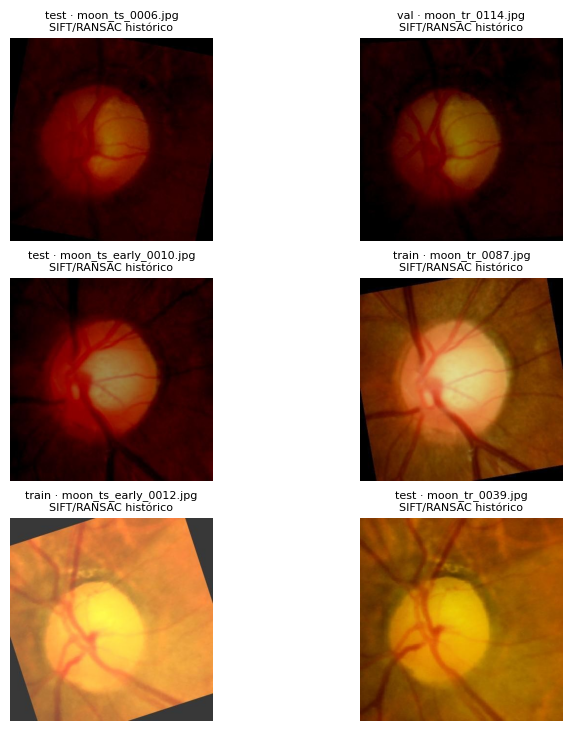

In [6]:
plot_links()

Los pares muestran variaciones en escala, color o encuadre que pueden conservar estructuras retinianas. Los ejemplos apoyan la revisión de procedencia y dejan abierta la identidad del paciente.

### Control de color y relleno

Se calculan promedios RGB sobre todo el archivo y los mismos detectores de negro y gris en esquinas de 4 × 4 de Andrés. Se presenta la señal por fuente y clase. El control logístico y la clase mayoritaria se entrenan con el train auditado de Moondream y se evalúan sobre el mismo test auditado, incluso en modo piloto. El control de color mide señal predictiva de esta representación y una intervención controlada sobre el mismo archivo sería necesaria para medir dependencia del ConvNeXt.

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

def full_image_color(image):
    pixels = np.asarray(image)
    corner_rgb = [block.reshape(-1, 3).mean(0) for block in (pixels[:4, :4], pixels[:4, -4:],
                                                             pixels[-4:, :4], pixels[-4:, -4:])]
    r, g, b = pixels.mean(axis=(0, 1))
    return {"R": r, "G": g, "B": b, "pad_negro": int(any(c.max() < 20 for c in corner_rgb)),
            "pad_gris": int(any(55 <= c.mean() <= 100 and np.ptp(c) < 8 for c in corner_rgb))}

def collect_color(rows):
    signals = pd.DataFrame([full_image_color(image_rgb(p)) for p in rows.id], index=rows.index)
    return pd.concat([rows, signals], axis=1)

Se cotejan medias por clase y resultados del clasificador RGB frente a la mayoría de entrenamiento.

In [8]:
if not ELIGIBLE.empty:
    audited_color = collect_color(ELIGIBLE)
    columns = ["R", "G", "B", "pad_negro", "pad_gris"]
    by_label = audited_color.groupby(["coleccion", "clase"], sort=False)[columns].agg(["size", "mean"])
    display(by_label.round(3))
    tr_color = audited_color.loc[audited_color.split.eq("train")]
    te_color = audited_color.loc[audited_color.split.eq("test")]
    rgb = ["R", "G", "B"]
    if tr_color.clase.nunique() == 3 and len(te_color):
        color_rows = []
        for label, classifier in (("RGB medio", LogisticRegression(max_iter=1000)),
                                  ("Clase mayoritaria en train", DummyClassifier(strategy="most_frequent"))):
            classifier.fit(tr_color[rgb], tr_color.y3.astype(int))
            pred = classifier.predict(te_color[rgb])
            stats, _ = metrics(te_color.y3.to_numpy(dtype=int), pred, 3)
            color_rows.append({"control": label, **stats, "exactitud binaria": np.mean((pred > 0) == te_color.y2)})
        display(pd.DataFrame(color_rows).round(3))

R             G             B         pad_negro  \
                          size     mean size     mean size    mean      size   
coleccion        clase                                                         
Moondream Staged normal    366  162.358  366  110.283  366  70.593       366   
                 advanced  177  164.680  177  102.588  177  47.847       177   
                 early     163  160.047  163  101.090  163  53.977       163   
ACRIMA           normal    308  178.896  308  108.162  308  31.852       308   
                 glaucoma  395  190.030  395   86.302  395  19.953       395   
RIM-ONE DL       glaucoma  162  147.050  162   69.159  162  37.619       162   
                 normal    285  150.423  285   64.705  285  35.688       285   
EyePACS REAL     glaucoma  100   86.261  100   55.454  100  36.689       100   
                 normal    100   89.393  100   55.605  100  35.743       100   

                                 pad_gris         
                            mean     size   mean  
coleccion        clase                            
Moondream Staged normal    0.527      366  0.142  
                 advanced  0.446      177  0.169  
                 early     0.491      163  0.196  
ACRIMA           normal    0.140      308  0.000  
                 glaucoma  0.078      395  0.000  
RIM-ONE DL       glaucoma  0.043      162  0.000  
                 normal    0.007      285  0.000  
EyePACS REAL     glaucoma  1.000      100  0.000  
                 normal    1.000      100  0.000

,control,n,F1 macro,exactitud,sensibilidad,especificidad,TFP,TFN,recall inicial,recall avanzado,QWK,errores adyacentes,errores sano ↔ avanzado,FN inicial,FN avanzado,exactitud binaria
0,RGB medio,95,0.382,0.558,0.391,0.857,0.143,0.609,0.0,0.44,0.282,21,21,14,14,0.632
1,Clase mayoritaria en train,95,0.227,0.516,0.000,1.000,0.000,1.000,0.0,0.00,0.000,21,25,21,25,0.516


## Resultados

### Modelo ganador de Andrés

Se recuperan los conteos guardados en las celdas de Evaluación y Resumen final de Andrés. Las sensibilidades por estadio y el desglose de FP/FN identifican las celdas de la matriz. Para pesos aportados se comprueban huella, arquitectura, cabeza `classifier[2]`, orden de etiquetas, época y τ. La regla oficial usa `1 − P(Sano)` y elige el más probable de los dos estadios cuando alcanza 0,95. La inferencia utiliza resize bilineal a 224 × 224 y normalización ImageNet, como en su preprocesamiento. La identidad exacta requiere confirmar los pesos por procedencia y el manifiesto por ruta.

,n,F1 macro,exactitud,sensibilidad,especificidad,TFP,TFN,recall inicial,recall avanzado,QWK,errores adyacentes,errores sano ↔ avanzado,FN inicial,FN avanzado
Andrés · salida guardada,115,0.722,0.774,0.804,0.932,0.068,0.196,0.519,0.69,0.713,19,7,6,5


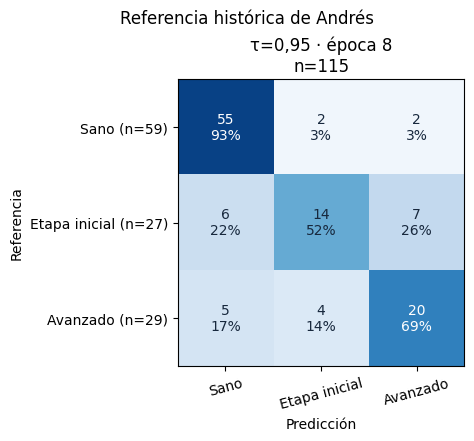

Checkpoint original ausente: C:\Users\fabi2\OneDrive\Escritorio\ProyectoDL-Grupo2-Glaucoma\modelos\convnext_tiny_final.pth
  backbone_screen_convnext_tiny.pth · cabeza (1, 768)
  best_fine_tuned_convnext_tiny_glaucoma.pth · cabeza (1, 768)


In [9]:
PUBLISHED_MATRIX = np.array([[55, 2, 2], [6, 14, 7], [5, 4, 20]])
published_y, published_pred = np.repeat(np.indices((3, 3)).reshape(2, -1), PUBLISHED_MATRIX.ravel(), axis=1)
published_metrics, _ = metrics(published_y, published_pred, 3)
display(pd.DataFrame([published_metrics], index=["Andrés · salida guardada"]).round(3))
matrices({"τ=0,95 · época 8": PUBLISHED_MATRIX}, CLASSES, "Referencia histórica de Andrés")

def original_decision(prob, tau):
    return np.where((1 - prob[:, 0]) >= tau, 1 + prob[:, 1:].argmax(1), 0)

def load_winner():
    if not CHECKPOINT.is_file():
        print(f"Checkpoint original ausente: {CHECKPOINT}")
        for candidate in (ROOT / "modelos").glob("*convnext_tiny*.pth"):
            payload = torch.load(candidate, map_location="cpu", weights_only=True)
            state = payload.get("state_dict", payload.get("model_state_dict", payload))
            weight = state.get("classifier.2.weight")
            print(f"  {candidate.name} · cabeza {tuple(weight.shape) if weight is not None else 'sin clave esperada'}")
        return None, False
    computed = digest(CHECKPOINT)
    print("SHA-256 del archivo aportado:", computed)
    if CHECKPOINT_SHA and computed != CHECKPOINT_SHA:
        print("La huella aportada difiere de la del archivo.")
        return None, False
    payload = torch.load(CHECKPOINT, map_location="cpu", weights_only=True)
    assert payload["clases"] == ["Sano", "Etapa inicial", "Glaucoma"]
    assert int(payload["epoca"]) == 8 and np.isclose(float(payload["tau"]), .95)
    assert tuple(payload["state_dict"]["classifier.2.weight"].shape) == (3, 768)
    model = make_convnext(3, pretrained=False)
    model.load_state_dict(payload["state_dict"], strict=True)
    trusted = bool(CHECKPOINT_SHA and REF_CONFIRMED)
    print("Metadatos, cabeza y esquema de pesos compatibles. Fuente exacta documentada:", trusted)
    return model, trusted

WINNER, WINNER_VERIFIED = load_winner()
WINNER_OUT = {}
WINNER_BIN_TAU = None
WINNER_TRI = None
if WINNER is not None and len(VAL):
    _, win_val = predict(WINNER, batches(VAL, 3))
    WINNER_BIN_TAU, spec = calibrate(VAL.y2.to_numpy(), win_val, 2)
    print(f"Umbral binario de Fabián: {WINNER_BIN_TAU:.2f}, especificidad validación {spec:.3f}")
    WINNER_OUT = evaluate_scenarios(WINNER, 3)
    if INTERNAL in EVAL_SETS:
        internal = EVAL_SETS[INTERNAL]
        win_pred = original_decision(WINNER_OUT[INTERNAL], .95)
        WINNER_TRI = metrics(internal.y3.to_numpy().astype(int), win_pred, 3)
        display(pd.DataFrame([WINNER_TRI[0]], index=["Checkpoint aportado · test elegible"]).round(3))
        matrices({"Regla original τ=0,95": WINNER_TRI[1]}, CLASSES, "Inferencia sobre las imágenes elegibles")
        if len(internal) == 115 and WINNER_VERIFIED:
            print("Coincidencia de matriz con publicación:", np.array_equal(WINNER_TRI[1], PUBLISHED_MATRIX))
    if WINNER_VERIFIED and not PILOT:
        parts = []
        for name, rows in EVAL_SETS.items():
            prob = WINNER_OUT[name]
            parts.append(pd.DataFrame({"id": rows.id, "cohorte": name, "y2": rows.y2,
                                       "y3": rows.y3, "p_binaria": p_positive(prob),
                                       "pred2_original": (1 - prob[:, 0] >= .95).astype(int),
                                       "pred3_original": original_decision(prob, .95),
                                       "sha256_archivo": rows.id.map(digest),
                                       "sha256_checkpoint": digest(CHECKPOINT)}))
        predictions = pd.concat(parts, ignore_index=True)
        predictions["sha256_split"] = scenario_signature(REF)
        predictions["sha256_elegibilidad"] = scenario_signature(ELIGIBLE[["id", "split", "grupo"]])
        predictions.to_csv(RUN / "predicciones_andres_verificadas.csv", index=False)

La matriz histórica suma 115 referencias, con soportes 59/27/29. La regla de Andrés detectó 45 de 56 positivos y produjo cuatro falsos positivos entre 59 sanos. Los conteos del nuevo test auditado corresponden a otro denominador. El QWK de la tabla se calcula a partir de los conteos publicados.

### Entrenamiento directo con dos clases

Las dos corridas usan la receta de entrenamiento de Andrés, con recorte aleatorio de escala 0,8–1, espejo horizontal, rotación hasta 15° y ajuste de color. Comparten elegibilidad, presupuesto y preentrenamiento ImageNet. La cabeza binaria se inicializa aleatoriamente y se entrena con Inicial y Avanzado recodificados como Positivo. Se excluyen del entrenamiento las fuentes con referencia exclusivamente binaria. Se registra el rendimiento trinario nuevo y una galería de errores internos.

Nueva corrida 3 clases · mejor época 10 · τ=0.81 · especificidad val.=0.981


Nueva corrida 2 clases · mejor época 3 · τ=0.90 · especificidad val.=0.962


,n,F1 macro,exactitud,sensibilidad,especificidad,TFP,TFN,recall inicial,recall avanzado,QWK,errores adyacentes,errores sano ↔ avanzado,FN inicial,FN avanzado
Nueva corrida trinaria,95,0.731,0.789,0.935,0.898,0.102,0.065,0.476,0.84,0.801,17,3,3,0


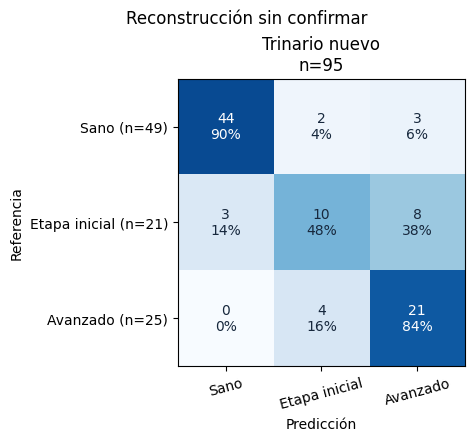

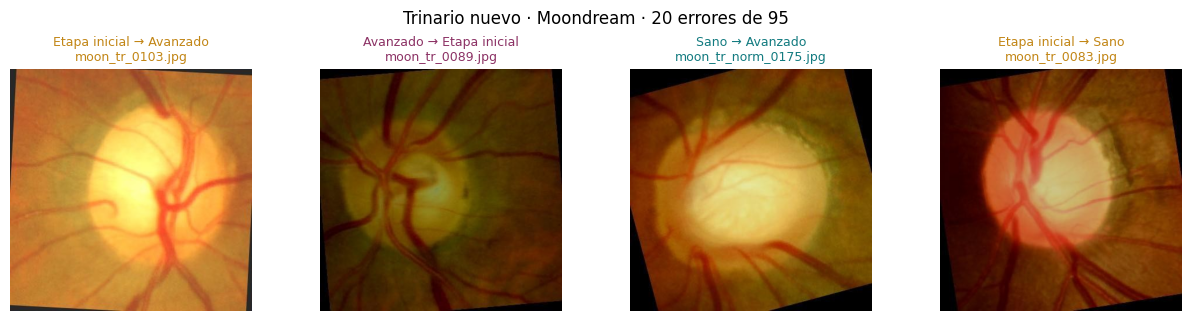

In [10]:
runs_one = {}
for task in (3, 2):
    fitted = fit(task, "Receta Andrés")
    if fitted is None:
        continue
    y_valid = VAL[f"y{task}"].to_numpy().astype(int)
    tau_task, spec_task = calibrate(y_valid, fitted["val_prob"], task)
    probabilities = evaluate_scenarios(fitted["model"], task)
    runs_one[task] = {"tau": tau_task, "spec": spec_task, "prob": probabilities, "hist": fitted["hist"],
                      "epoca": fitted["epoca"], "peso": fitted["peso"]}
    if task == 3:
        runs_one[task]["bin_tau"], runs_one[task]["bin_spec"] = calibrate(VAL.y2.to_numpy(), fitted["val_prob"], 2)
    print(f"Nueva corrida {task} clases · mejor época {fitted['epoca']} · τ={tau_task:.2f} · especificidad val.={spec_task:.3f}")
    del fitted

if 3 in runs_one and INTERNAL in EVAL_SETS:
    tri = runs_one[3]
    rows = EVAL_SETS[INTERNAL]
    truth = rows.y3.to_numpy(dtype=int)
    pred = decide(tri["prob"][INTERNAL], tri["tau"])
    result, cm = metrics(truth, pred, 3)
    display(pd.DataFrame([result], index=["Nueva corrida trinaria"]).round(3))
    matrices({"Trinario nuevo": cm}, CLASSES, REF_STATUS)
    error_gallery(rows, truth, pred, CLASSES, "Trinario nuevo · Moondream")

La matriz nueva separa la severidad de la detección. Un salto Sano↔Avanzado pesa más que los errores adyacentes en QWK. La galería muestra ejemplos seleccionados por tipo de confusión y permite inspeccionar el encuadre y la apariencia de cada caso.

### Detección binaria por cohorte

Se suma `P(Inicial) + P(Avanzado)`. Se calibra su umbral con F1 macro y sensibilidad **binarios** en validación. Este objetivo es nuevo. Se añade la proyección binaria de la regla histórica a 0,95 cuando están los pesos correspondientes. Las matrices, ROC, precisión–recobrado, galerías e intervalos usan los mismos archivos para los modelos comparados. Cada fuente tiene su propio denominador.

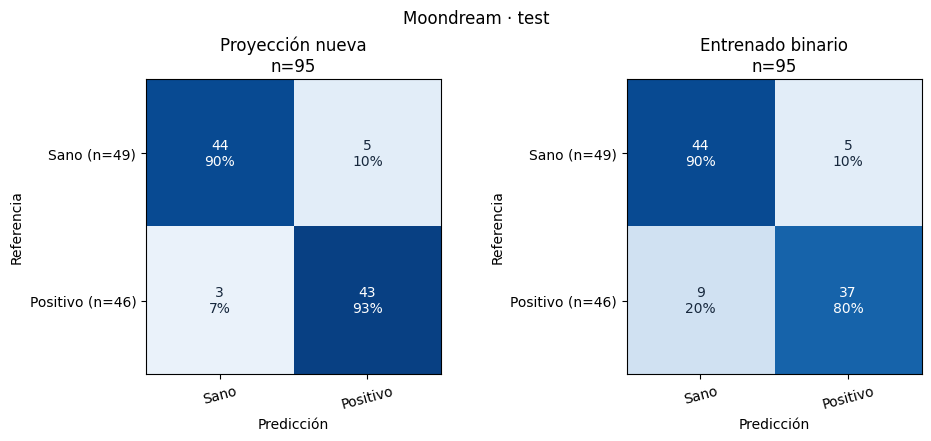

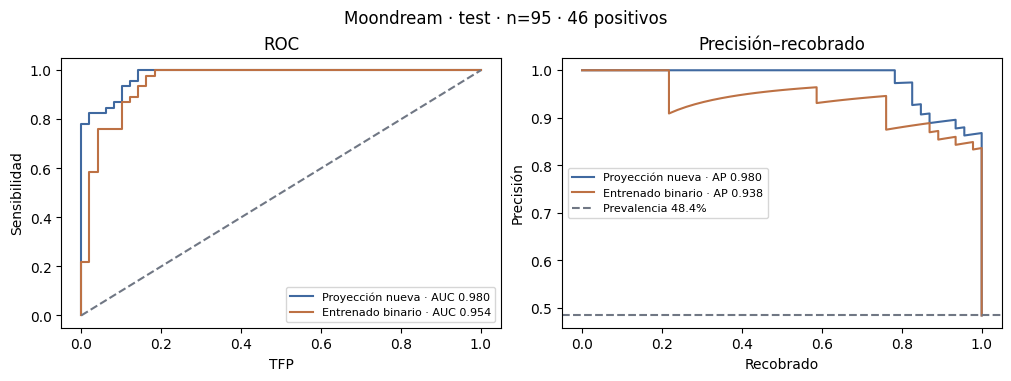

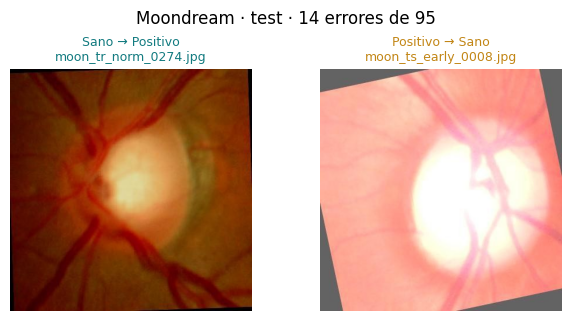

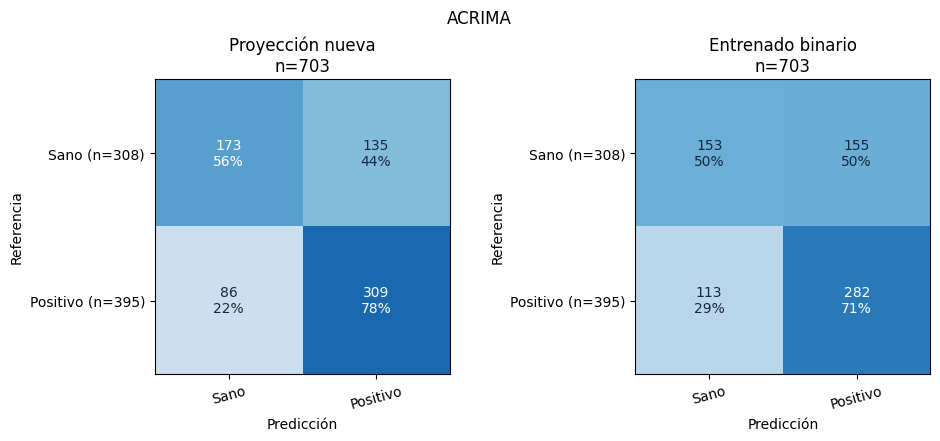

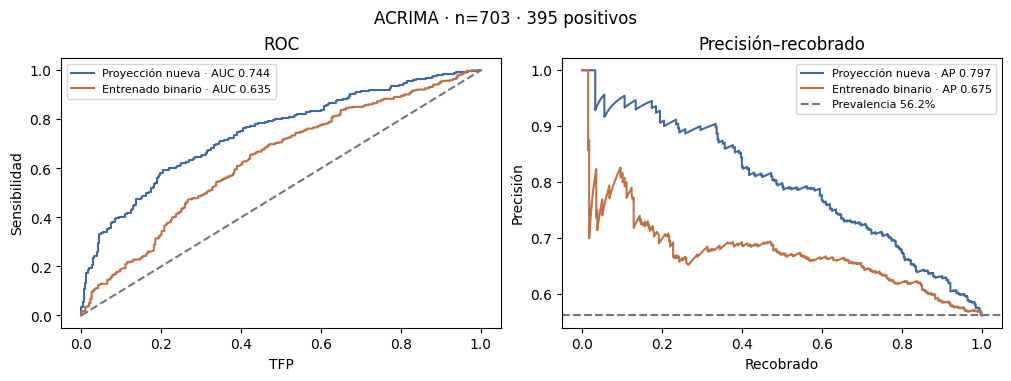

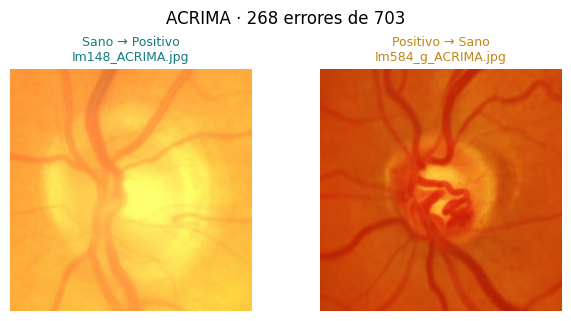

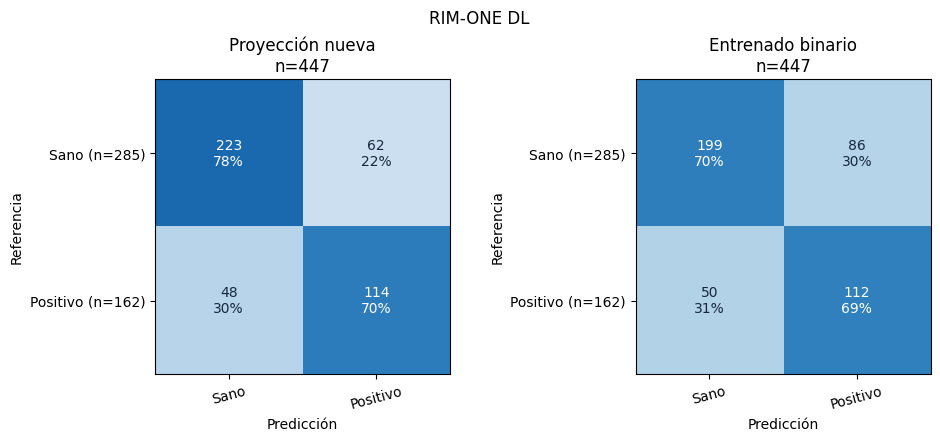

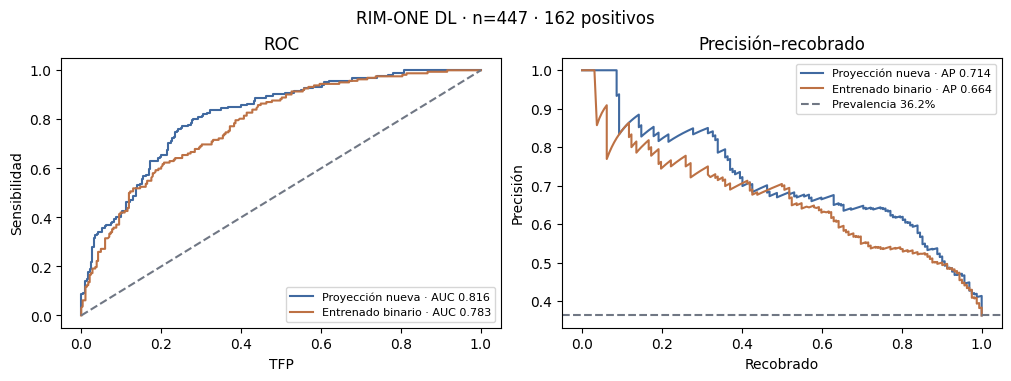

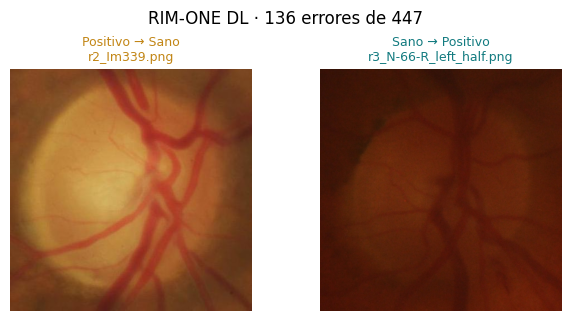

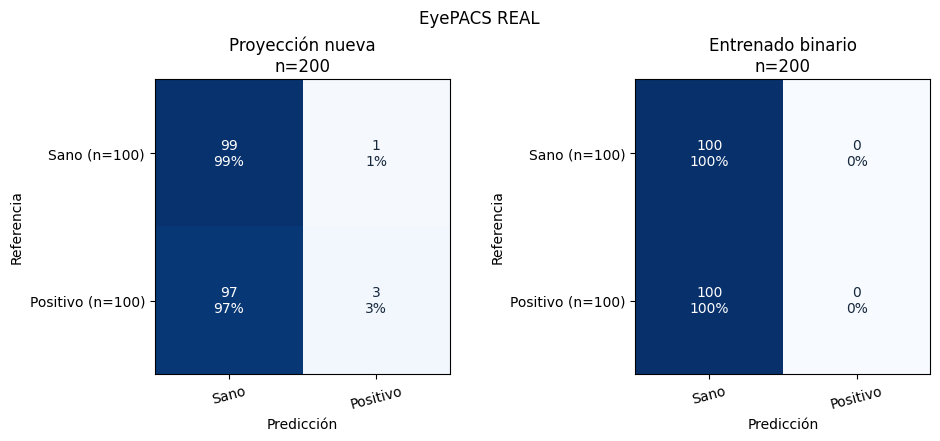

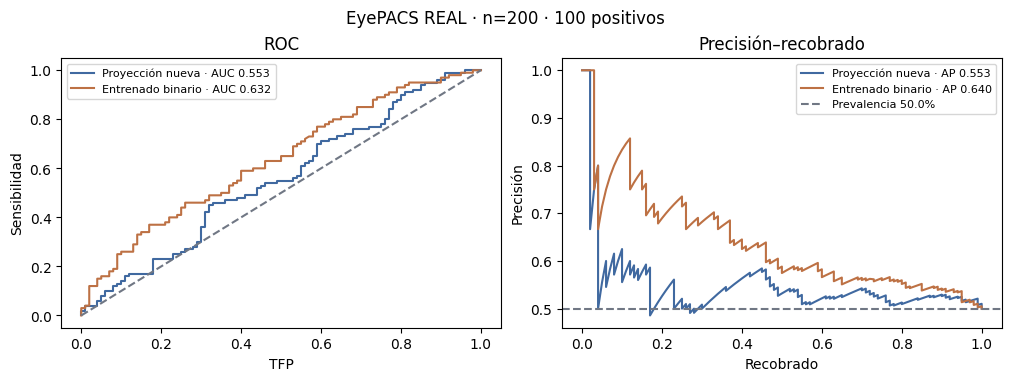

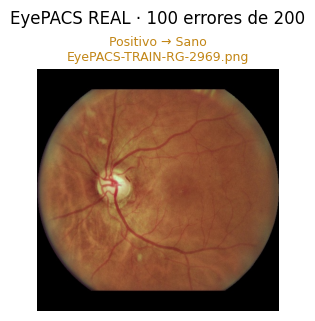

Umbral de la proyección nueva 0.81; especificidad de validación 0.981


,cohorte,modelo,n,F1 macro,exactitud,sensibilidad,especificidad,TFP,TFN,FP,FN,AUROC,AP
0,Moondream · test,Proyección nueva,95,0.916,0.916,0.935,0.898,0.102,0.065,5,3,0.980,0.980
1,Moondream · test,Entrenado binario,95,0.852,0.853,0.804,0.898,0.102,0.196,5,9,0.954,0.938
2,ACRIMA,Proyección nueva,703,0.673,0.686,0.782,0.562,0.438,0.218,135,86,0.744,0.797
3,ACRIMA,Entrenado binario,703,0.605,0.619,0.714,0.497,0.503,0.286,155,113,0.635,0.675
4,RIM-ONE DL,Proyección nueva,447,0.738,0.754,0.704,0.782,0.218,0.296,62,48,0.816,0.714
5,RIM-ONE DL,Entrenado binario,447,0.684,0.696,0.691,0.698,0.302,0.309,86,50,0.783,0.664
6,EyePACS REAL,Proyección nueva,200,0.363,0.510,0.030,0.990,0.010,0.970,1,97,0.553,0.553
7,EyePACS REAL,Entrenado binario,200,0.333,0.500,0.000,1.000,0.000,1.000,0,100,0.632,0.640


,medida,delta,p2.5,p97.5,cohorte,referencia,n
0,F1 macro,-0.064,-0.139,0.011,Moondream · test,Proyección nueva,95
1,sensibilidad,-0.130,-0.261,-0.022,Moondream · test,Proyección nueva,95
2,especificidad,0.000,-0.102,0.102,Moondream · test,Proyección nueva,95
3,F1 macro,-0.068,-0.098,-0.040,ACRIMA,Proyección nueva,703
4,sensibilidad,-0.068,-0.104,-0.030,ACRIMA,Proyección nueva,703
5,especificidad,-0.065,-0.110,-0.023,ACRIMA,Proyección nueva,703
6,F1 macro,-0.055,-0.095,-0.015,RIM-ONE DL,Proyección nueva,447
7,sensibilidad,-0.012,-0.080,0.056,RIM-ONE DL,Proyección nueva,447
8,especificidad,-0.084,-0.130,-0.042,RIM-ONE DL,Proyección nueva,447
9,F1 macro,-0.030,-0.068,0.002,EyePACS REAL,Proyección nueva,200


In [11]:
binary_records, intervals, predictions_one = [], [], []
for source, rows in EVAL_SETS.items():
    scores, decisions = {}, {}
    if WINNER_OUT:
        scores["Proyección original"] = p_positive(WINNER_OUT[source])
        decisions["Proyección original"] = (scores["Proyección original"] >= WINNER_BIN_TAU).astype(int)
        decisions["Regla histórica 0,95"] = (1 - WINNER_OUT[source][:, 0] >= .95).astype(int)
        scores["Regla histórica 0,95"] = scores["Proyección original"]
    for task, name in ((3, "Proyección nueva"), (2, "Entrenado binario")):
        if task in runs_one:
            model_run = runs_one[task]
            scores[name] = p_positive(model_run["prob"][source])
            tau_used = model_run.get("bin_tau", model_run["tau"])
            decisions[name] = (scores[name] >= tau_used).astype(int)
    truth = rows.y2.to_numpy()
    panel = {}
    for name, pred in decisions.items():
        stats, cm = summarize_binary(truth, pred, scores[name])
        binary_records.append({"cohorte": source, "modelo": name, **stats})
        panel[name] = cm
        predictions_one.append(rows[["id", "clase", "grupo", "y2"]].assign(
            cohorte=source, modelo=name, pred=pred, prob=scores[name]))
    if not panel:
        continue
    matrices(panel, BINARY, source)
    binary_curves(rows, {model: p for model, p in scores.items() if model != "Regla histórica 0,95"}, source)
    if "Entrenado binario" in decisions:
        error_gallery(rows, truth, decisions["Entrenado binario"], BINARY, source)
        for baseline in ("Proyección nueva", "Proyección original"):
            if baseline in decisions:
                result = paired_delta(rows, truth, decisions[baseline], decisions["Entrenado binario"], 2)
                if len(result):
                    intervals.append(result.assign(cohorte=source, referencia=baseline, n=len(rows)))
if 3 in runs_one and "bin_tau" in runs_one[3]:
    print(f"Umbral de la proyección nueva {runs_one[3]['bin_tau']:.2f}; especificidad de validación {runs_one[3]['bin_spec']:.3f}")
if binary_records:
    summary_one = pd.DataFrame(binary_records)
    display(summary_one.round(3))
    summary_one.to_csv(RUN / "01_metricas_binarias.csv", index=False)
    pd.concat(predictions_one).to_csv(RUN / "01_predicciones_binarias.csv", index=False)
if intervals:
    display(pd.concat(intervals, ignore_index=True).round(3))

Las matrices muestran el intercambio entre FN y FP al umbral elegido. ROC y precisión–recobrado evalúan la ordenación de los puntajes y la línea de prevalencia da contexto en cada cohorte. Para las galerías se toma un ejemplo por tipo de error. La cifra de EyePACS REAL depende de las etiquetas RG/NRG locales.

## Interpretación y limitaciones

Se leen las diferencias en puntos porcentuales con la dirección binario entrenado menos proyección. La incertidumbre depende de la cobertura de los grupos visuales y una sola semilla de entrenamiento. Las cohortes externas solo aportan referencia para detección. Con la partición reconstruida y el checkpoint publicado ausente, la evidencia ejecutada sobre modelos nuevos se interpreta como comparación experimental sobre la vista elegible.

In [12]:
if binary_records:
    for source, source_report in summary_one.groupby("cohorte", sort=False):
        paired = source_report.set_index("modelo")
        if {"Entrenado binario", "Proyección nueva"}.issubset(paired.index):
            columns = ["F1 macro", "sensibilidad", "especificidad"]
            diff = paired.loc["Entrenado binario", columns] - paired.loc["Proyección nueva", columns]
            print(f"{source} (n={int(paired.iloc[0].n)}) · binario − proyección nueva: "
                  f"Δ F1 macro {100 * diff['F1 macro']:+.1f} pp; Δ sensibilidad {100 * diff.sensibilidad:+.1f} pp; "
                  f"Δ especificidad {100 * diff.especificidad:+.1f} pp.")
    if PILOT:
        print("Piloto: una sola época de ajuste y muestra limitada. Estas diferencias verifican el flujo de evaluación.")

Moondream · test (n=95) · binario − proyección nueva: Δ F1 macro -6.4 pp; Δ sensibilidad -13.0 pp; Δ especificidad +0.0 pp.
ACRIMA (n=703) · binario − proyección nueva: Δ F1 macro -6.8 pp; Δ sensibilidad -6.8 pp; Δ especificidad -6.5 pp.
RIM-ONE DL (n=447) · binario − proyección nueva: Δ F1 macro -5.5 pp; Δ sensibilidad -1.2 pp; Δ especificidad -8.4 pp.
EyePACS REAL (n=200) · binario − proyección nueva: Δ F1 macro -3.0 pp; Δ sensibilidad -3.0 pp; Δ especificidad +1.0 pp.


En el test auditado de Moondream (n=95), el F1 macro binario fue **0,916** con la proyección y **0,852** con la cabeza binaria. Los modelos tuvieron la misma especificidad (89.8 %) y la proyección detectó seis positivos más. En EyePACS REAL (n=200), ambos umbrales calibrados en Moondream dejaron la sensibilidad en 3 % o menos frente a la referencia RG/NRG. El control RGB obtuvo exactitud 0,558 frente a 0,516 para la mayoría en el mismo test interno. Ese resultado mide información de color disponible para un clasificador simple.